# Load Data and Dictionaries from previous IR project

In [2]:
from pathlib import Path

old_project = Path("external") / "llm-query-expansion-retrieval"

In [3]:
from beir.datasets.data_loader import GenericDataLoader

corpus, queries, qrels = GenericDataLoader(
    old_project / "scifact"
).load(split="test")

C:\Users\lenovo\nlp_env\Lib\site-packages\beir\datasets\data_loader.py:8: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from tqdm.autonotebook import tqdm
100%|███████████████████████████████████████████████████████████████████████████| 5183/5183 [00:00<00:00, 39956.47it/s]


In [5]:
import pickle

with open( old_project / "data/expanded_run_dict.pkl", "rb") as f:
    expanded_run_dict = pickle.load(f)

In [7]:
import pickle

with open( old_project / "data/original_run_dict.pkl", "rb") as f:
    run_dict = pickle.load(f)

In [8]:
common_dict = {}

for query_id in expanded_run_dict:
    expanded_docs = expanded_run_dict[query_id].keys()
    original_docs = run_dict[query_id].keys()

    common_dict[query_id] = list(
        set(expanded_docs) & set(original_docs)
    )

In [9]:
import pandas as pd

intersection_df = pd.DataFrame({
    'query_id': common_dict.keys(),
    'doc_ids': list(common_dict.values()),
    'intersection': [len(docs) for docs in common_dict.values()]
})

### DFs

In [11]:
df_per_expquery = pd.read_pickle(old_project / "data/df_per_expquery.pkl")

In [13]:
df_per_query = pd.read_pickle(old_project / "data/df_per_query.pkl")

In [14]:
df_per_expquery['recall@5-expanded'] = df_per_expquery['recall@5']
df_per_expquery['recall@10-expanded'] = df_per_expquery['recall@10']
df_per_expquery['mrr@10-expanded'] = df_per_expquery['mrr@10']
df_per_expquery['ndcg@10-expanded'] = df_per_expquery['ndcg@10']
df_per_expquery = df_per_expquery.drop(columns = ['ndcg@10', 'mrr@10', 'recall@5', 'recall@10'])

In [15]:
df_per_query['recall@5-original'] = df_per_query['recall@5']
df_per_query['recall@10-original'] = df_per_query['recall@10']
df_per_query['mrr@10-original'] = df_per_query['mrr@10']
df_per_query['ndcg@10-original'] = df_per_query['ndcg@10']
df_per_query = df_per_query.drop(columns = ['ndcg@10', 'mrr@10', 'recall@5', 'recall@10'])

In [16]:
Evaluation = intersection_df.merge(df_per_query, on='query_id').merge(df_per_expquery, on = "query_id")

In [17]:
Evaluation

,query_id,doc_ids,intersection,recall@5-original,recall@10-original,mrr@10-original,ndcg@10-original,recall@5-expanded,recall@10-expanded,mrr@10-expanded,ndcg@10-expanded
0,1,"[13231899, 24998637, 10931595]",3,0.00,0.0,0.000000,0.000000,0.0,0.00,0.000,0.000000
1,3,"[14717500, 23389795, 4414547, 3672261, 1351966...",7,1.00,1.0,0.333333,0.500000,1.0,1.00,1.000,1.000000
2,5,"[13734012, 1292369, 17333231, 18617259, 695938...",6,1.00,1.0,1.000000,1.000000,1.0,1.00,1.000,1.000000
3,13,"[7662395, 1263446, 2425364, 17450673, 5487448]",5,0.00,0.0,0.000000,0.000000,0.0,0.00,0.000,0.000000
4,36,"[11705328, 42441846, 33409100, 21636085, 37424...",7,0.00,0.5,0.166667,0.218407,0.0,0.50,0.125,0.193426
...,...,...,...,...,...,...,...,...,...,...,...
295,1379,"[8842332, 38784540, 16098747, 17450673, 374801...",8,0.25,0.5,0.333333,0.334246,0.5,0.75,0.500,0.564644
296,1382,"[3831884, 1344498, 4138659, 3085264, 28334217]",5,0.00,0.0,0.000000,0.000000,0.0,0.00,0.000,0.000000
297,1385,"[9283422, 306006]",2,1.00,1.0,1.000000,1.000000,1.0,1.00,0.500,0.630930
298,1389,[23895668],1,1.00,1.0,1.000000,1.000000,1.0,1.00,1.000,1.000000


# Scatter Plot

In [18]:
Evaluation['delta_ndcg'] = (
    Evaluation['ndcg@10-original'] - Evaluation['ndcg@10-expanded'])

In [19]:
x = Evaluation['intersection']
y = Evaluation['delta_ndcg']

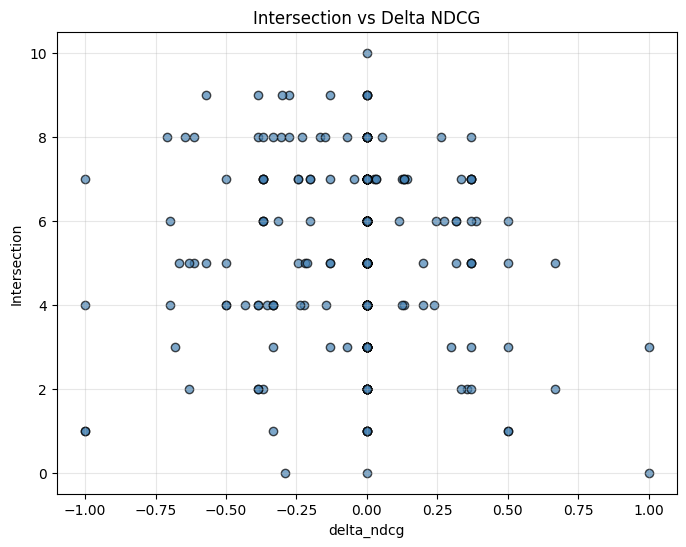

In [20]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.scatter(Evaluation['delta_ndcg'], 
            Evaluation['intersection'],
            alpha=0.7,
            color='steelblue',
            edgecolors='black')

plt.xlabel('delta_ndcg')
plt.ylabel('Intersection')
plt.title('Intersection vs Delta NDCG')
plt.grid(True, alpha=0.3)
plt.show()

# Extra Investigation

In [21]:
orig_better = Evaluation.loc[Evaluation['delta_ndcg'] > 0]
len(orig_better)

46

In [22]:
equal = Evaluation.loc[Evaluation['delta_ndcg'] == 0]
len(equal)

183

In [23]:
exp_better = Evaluation.loc[Evaluation['delta_ndcg'] < 0]
len(exp_better)

71

In [24]:
orig_better

,query_id,doc_ids,intersection,recall@5-original,recall@10-original,mrr@10-original,ndcg@10-original,recall@5-expanded,recall@10-expanded,mrr@10-expanded,ndcg@10-expanded,delta_ndcg
4,36,"[11705328, 42441846, 33409100, 21636085, 37424...",7,0.000000,0.5,0.166667,0.218407,0.000000,0.5,0.125000,0.193426,0.024981
6,48,"[13734012, 13959707, 8524891, 18617259, 11349166]",5,1.000000,1.0,0.500000,0.630930,1.000000,1.0,0.250000,0.430677,0.200253
14,70,"[24721866, 21307488, 5956380, 43880096, 119032...",6,1.000000,1.0,1.000000,1.000000,0.500000,0.5,1.000000,0.613147,0.386853
19,100,[4381486],1,1.000000,1.0,1.000000,1.000000,1.000000,1.0,0.333333,0.500000,0.500000
25,128,"[8290953, 23513718, 1122279, 19685306, 1263118...",7,1.000000,1.0,0.333333,0.500000,0.000000,1.0,0.166667,0.356207,0.143793
31,141,"[38794814, 14437255, 3099497, 6431384, 3686085...",7,1.000000,1.0,1.000000,1.000000,1.000000,1.0,1.000000,0.877215,0.122785
36,163,"[29022271, 40949706, 43220289, 5824985, 762716...",7,1.000000,1.0,1.000000,1.000000,1.000000,1.0,0.500000,0.630930,0.369070
41,185,"[18340282, 22401720, 21874312, 3524352]",4,1.000000,1.0,0.500000,0.630930,1.000000,1.0,0.250000,0.430677,0.200253
60,268,"[970012, 1568684, 4319174, 32955023, 36838958,...",6,1.000000,1.0,1.000000,1.000000,1.000000,1.0,0.333333,0.500000,0.500000
61,269,"[970012, 1568684, 4319174, 36838958, 34582256,...",6,1.000000,1.0,0.500000,0.630930,0.000000,1.0,0.125000,0.315465,0.315465


In [25]:
exp_better

,query_id,doc_ids,intersection,recall@5-original,recall@10-original,mrr@10-original,ndcg@10-original,recall@5-expanded,recall@10-expanded,mrr@10-expanded,ndcg@10-expanded,delta_ndcg
1,3,"[14717500, 23389795, 4414547, 3672261, 1351966...",7,1.00,1.0,0.333333,0.500000,1.0,1.00,1.000000,1.000000,-0.500000
15,72,"[10937190, 6076903]",2,1.00,1.0,0.500000,0.630930,1.0,1.00,1.000000,1.000000,-0.369070
16,75,"[22703082, 4387784, 25657127, 13965483, 283775...",9,1.00,1.0,0.333333,0.500000,1.0,1.00,0.500000,0.630930,-0.130930
24,127,"[35231675, 38623601, 4421547, 21598000, 7549811]",5,1.00,1.0,0.250000,0.430677,1.0,1.00,1.000000,1.000000,-0.569323
28,132,"[27615329, 45401535, 58006489, 21181273]",4,0.00,0.0,0.000000,0.000000,0.0,1.00,0.142857,0.333333,-0.333333
...,...,...,...,...,...,...,...,...,...,...,...,...
280,1316,"[18834078, 27243019, 43587663, 20610557]",4,0.00,0.0,0.000000,0.000000,1.0,1.00,0.333333,0.500000,-0.500000
281,1319,"[9122283, 12742164, 14192687, 16284655]",4,1.00,1.0,0.333333,0.500000,1.0,1.00,1.000000,1.000000,-0.500000
293,1368,"[13312471, 23267371, 30720103, 22023404, 21553...",7,0.00,0.0,0.000000,0.000000,1.0,1.00,1.000000,1.000000,-1.000000
294,1370,"[2425364, 13312471, 23267371, 30720103, 215533...",7,1.00,1.0,0.200000,0.386853,1.0,1.00,0.500000,0.630930,-0.244077


In [26]:
# Let's check the length of the queries.
orig_better['query_text'] = orig_better['query_id'].map(queries)

In [27]:
exp_better['query_text'] = exp_better['query_id'].map(queries)
exp_better

,query_id,doc_ids,intersection,recall@5-original,recall@10-original,mrr@10-original,ndcg@10-original,recall@5-expanded,recall@10-expanded,mrr@10-expanded,ndcg@10-expanded,delta_ndcg,query_text
1,3,"[14717500, 23389795, 4414547, 3672261, 1351966...",7,1.00,1.0,0.333333,0.500000,1.0,1.00,1.000000,1.000000,-0.500000,"1,000 genomes project enables mapping of genet..."
15,72,"[10937190, 6076903]",2,1.00,1.0,0.500000,0.630930,1.0,1.00,1.000000,1.000000,-0.369070,Activator-inhibitor pairs are provided dorsall...
16,75,"[22703082, 4387784, 25657127, 13965483, 283775...",9,1.00,1.0,0.333333,0.500000,1.0,1.00,0.500000,0.630930,-0.130930,Active H. pylori urease has a polymeric struct...
24,127,"[35231675, 38623601, 4421547, 21598000, 7549811]",5,1.00,1.0,0.250000,0.430677,1.0,1.00,1.000000,1.000000,-0.569323,Arginine 90 in p150n is important for interact...
28,132,"[27615329, 45401535, 58006489, 21181273]",4,0.00,0.0,0.000000,0.000000,0.0,1.00,0.142857,0.333333,-0.333333,Aspirin inhibits the production of PGE2.
...,...,...,...,...,...,...,...,...,...,...,...,...,...
280,1316,"[18834078, 27243019, 43587663, 20610557]",4,0.00,0.0,0.000000,0.000000,1.0,1.00,0.333333,0.500000,-0.500000,Transferred UCB T cells acquire a memory-like ...
281,1319,"[9122283, 12742164, 14192687, 16284655]",4,1.00,1.0,0.333333,0.500000,1.0,1.00,1.000000,1.000000,-0.500000,Transplanted human glial cells can differentia...
293,1368,"[13312471, 23267371, 30720103, 22023404, 21553...",7,0.00,0.0,0.000000,0.000000,1.0,1.00,1.000000,1.000000,-1.000000,Vitamin D deficiency effects the term of deliv...
294,1370,"[2425364, 13312471, 23267371, 30720103, 215533...",7,1.00,1.0,0.200000,0.386853,1.0,1.00,0.500000,0.630930,-0.244077,Vitamin D deficiency is unrelated to birth wei...


# Extend the dataset with more attributes

In [28]:
original_relevant = {
    query_id: float(
        len(
            set(relevant_docs) &
            set(run_dict.get(query_id, {}))
        )
        / len(relevant_docs)
    )
    for query_id, relevant_docs in qrels.items()
}
Evaluation['original_relevant@10'] = (
    Evaluation['query_id'].map(original_relevant)
)

In [29]:
expanded_relevant = {
    query_id: float(
        len(
            set(relevant_docs) &
            set(expanded_run_dict.get(query_id, {}))
        )
        / len(relevant_docs)
    )
    for query_id, relevant_docs in qrels.items()
}
Evaluation['expanded_relevant@10'] = (
    Evaluation['query_id'].map(expanded_relevant)
)

### New Relevant

In [30]:
new_relevant_docs = {
    query_id: len(list(
        set(expanded_run_dict.get(query_id, {}))
        & set(qrels.get(query_id, {}))
        - set(run_dict.get(query_id, {}))
    ))
    for query_id in expanded_run_dict
}

Evaluation['new_relevant'] = Evaluation['query_id'].map(new_relevant_docs)

In [31]:
Evaluation

,query_id,doc_ids,intersection,recall@5-original,recall@10-original,mrr@10-original,ndcg@10-original,recall@5-expanded,recall@10-expanded,mrr@10-expanded,ndcg@10-expanded,delta_ndcg,original_relevant@10,expanded_relevant@10,new_relevant
0,1,"[13231899, 24998637, 10931595]",3,0.00,0.0,0.000000,0.000000,0.0,0.00,0.000,0.000000,0.000000,0.0,0.00,0
1,3,"[14717500, 23389795, 4414547, 3672261, 1351966...",7,1.00,1.0,0.333333,0.500000,1.0,1.00,1.000,1.000000,-0.500000,1.0,1.00,0
2,5,"[13734012, 1292369, 17333231, 18617259, 695938...",6,1.00,1.0,1.000000,1.000000,1.0,1.00,1.000,1.000000,0.000000,1.0,1.00,0
3,13,"[7662395, 1263446, 2425364, 17450673, 5487448]",5,0.00,0.0,0.000000,0.000000,0.0,0.00,0.000,0.000000,0.000000,0.0,0.00,0
4,36,"[11705328, 42441846, 33409100, 21636085, 37424...",7,0.00,0.5,0.166667,0.218407,0.0,0.50,0.125,0.193426,0.024981,0.5,0.50,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
295,1379,"[8842332, 38784540, 16098747, 17450673, 374801...",8,0.25,0.5,0.333333,0.334246,0.5,0.75,0.500,0.564644,-0.230397,0.5,0.75,1
296,1382,"[3831884, 1344498, 4138659, 3085264, 28334217]",5,0.00,0.0,0.000000,0.000000,0.0,0.00,0.000,0.000000,0.000000,0.0,0.00,0
297,1385,"[9283422, 306006]",2,1.00,1.0,1.000000,1.000000,1.0,1.00,0.500,0.630930,0.369070,1.0,1.00,0
298,1389,[23895668],1,1.00,1.0,1.000000,1.000000,1.0,1.00,1.000,1.000000,0.000000,1.0,1.00,0


### Lost Relevant

In [32]:
lost_relevant_docs = {
    query_id: len(list(
        set(run_dict.get(query_id, {}))
        & set(qrels.get(query_id, {}))
        - set(expanded_run_dict.get(query_id, {}))
    ))
    for query_id in expanded_run_dict
}

Evaluation['lost_relevant'] = Evaluation['query_id'].map(lost_relevant_docs)

### Query Length

In [33]:
# we will just remove punctuations and apply lower()
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
import string

nltk.download("punkt")
nltk.download("punkt_tab")

def preprocess(text):
    tokens = word_tokenize(text.lower())
    return [
        token for token in tokens
        if token not in string.punctuation
        and token not in {"+", "=", "-", "/", "*"}
    ]

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\lenovo\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\lenovo\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [34]:
def cal_query_len(query):
    return len(preprocess(query))

Evaluation['query_len'] = (
    Evaluation['query_id']
    .map(queries)
    .apply(cal_query_len)
)

In [35]:
with open(old_project / "data/expanded_queries_dict.pkl", "rb") as f:
    expanded_queries_dict = pickle.load(f)

In [36]:
def cal_query_len(query):
    return len(preprocess(query))

Evaluation['exp_query_len'] = (
    Evaluation['query_id']
    .map(expanded_queries_dict)
    .apply(cal_query_len)
)

### Query Expansion Sim

In [37]:
from sentence_transformers import SentenceTransformer

In [38]:
embedding_model = SentenceTransformer("BAAI/bge-base-en-v1.5")

Loading weights: 100%|█████████████████████████████████████████████████████████████| 199/199 [00:00<00:00, 1011.98it/s]


In [39]:
original_queries_list = list(val for key,val in queries.items())

In [40]:
import time

start_time = time.time()

or_query_embedding = embedding_model.encode(
    original_queries_list,
    batch_size=32,
    show_progress_bar=True,
    normalize_embeddings=True
)

end_time = time.time()

print(f"Encoding took {end_time - start_time:.2f} seconds")
print(or_query_embedding.shape)

Batches: 100%|█████████████████████████████████████████████████████████████████████████| 10/10 [00:24<00:00,  2.42s/it]

Encoding took 24.23 seconds
(300, 768)


In [41]:
expanded_queries_list = list(val for key,val in expanded_queries_dict.items())

In [42]:
import time

start_time = time.time()

exp_query_embedding = embedding_model.encode(
    expanded_queries_list,
    batch_size=32,
    show_progress_bar=True,
    normalize_embeddings=True
)

end_time = time.time()

print(f"Encoding took {end_time - start_time:.2f} seconds")
print(exp_query_embedding.shape)

Batches: 100%|█████████████████████████████████████████████████████████████████████████| 10/10 [01:01<00:00,  6.17s/it]

Encoding took 61.68 seconds
(300, 768)


In [43]:
from sklearn.metrics.pairwise import cosine_similarity

cosine_lst = []
for i, j in zip(exp_query_embedding, or_query_embedding):
    sim = cosine_similarity(i.reshape(1, -1), j.reshape(1, -1))
    cosine_lst.append(sim[0][0])

In [44]:
cosine_lst

[np.float32(0.8696868),
 np.float32(0.932769),
 np.float32(0.86552),
 np.float32(0.87234604),
 np.float32(0.9416207),
 np.float32(0.9577917),
 np.float32(0.89357054),
 np.float32(0.90850866),
 np.float32(0.8941783),
 np.float32(0.9259329),
 np.float32(0.9256086),
 np.float32(0.9398066),
 np.float32(0.9479847),
 np.float32(0.95319355),
 np.float32(0.8797292),
 np.float32(0.8863106),
 np.float32(0.9392171),
 np.float32(0.9220021),
 np.float32(0.9123038),
 np.float32(0.92066693),
 np.float32(0.9506136),
 np.float32(0.8729044),
 np.float32(0.9365695),
 np.float32(0.9044807),
 np.float32(0.92124134),
 np.float32(0.9172827),
 np.float32(0.86719644),
 np.float32(0.8650223),
 np.float32(0.90184957),
 np.float32(0.96707624),
 np.float32(0.91003954),
 np.float32(0.88521004),
 np.float32(0.9636286),
 np.float32(0.95313627),
 np.float32(0.95783067),
 np.float32(0.92374617),
 np.float32(0.909825),
 np.float32(0.9286569),
 np.float32(0.9095762),
 np.float32(0.911742),
 np.float32(0.8846227),
 np.flo

In [45]:
Evaluation['cosine_similarity'] = cosine_lst

In [46]:
def whichone(row):
    if row > 0:
        return "original"
    elif row < 0:
        return "expanded"
    else :
        return "equal"

Evaluation['original_or_expanded'] = Evaluation['delta_ndcg'].apply(whichone)

### Rank Displacement

In [47]:
ret_original = []
for key, val in run_dict.items():
    ret_original.append(list(set(val)))

In [48]:
ret_expanded = []
for key, val in expanded_run_dict.items():
    ret_expanded.append(list(set(val)))

In [49]:
def rank_displacement(original_docs, expanded_docs):
    original_rank = {
        doc: rank
        for rank, doc in enumerate(original_docs, start=1)
    }

    expanded_rank = {
        doc: rank
        for rank, doc in enumerate(expanded_docs, start=1)
    }

    common_docs = set(original_docs) & set(expanded_docs)

    if not common_docs:
        return 0

    displacements = [
        abs(original_rank[doc] - expanded_rank[doc])
        for doc in common_docs
    ]

    return sum(displacements) / len(displacements)

In [50]:
Evaluation["expanded_docs"] = ret_expanded 
Evaluation["original_docs"] = ret_original

Evaluation["mean_rank_displacement"] = Evaluation.apply(
    lambda row: rank_displacement(
        row["original_docs"],
        row["expanded_docs"]
    ),
    axis=1
)

### Expansion_Ratio

In [51]:
Evaluation['expansion_ratio'] = Evaluation['exp_query_len'] / Evaluation['query_len']

### Query Term Coverage

In [52]:
expanded_queries_df = pd.read_csv(
    old_project / "scifact_gemini_expanded_queries.csv",
    dtype={"query_id": str}
)

In [53]:
expanded_queries_df['expanded_ret_docs_ids'] = expanded_queries_df['query_id'].map(
    lambda qid: list(expanded_run_dict[qid].keys())
)

In [54]:
corpus_df = pd.read_pickle( old_project /"data/corpus_df.pkl")

In [55]:
docs_lookup = dict(zip(corpus_df['index'], corpus_df['docs']))

def query_coverage(ids_lst, query, docs_lookup):
    
    query_tokens = set(preprocess(query))
    retrieved_tokens = set()

    for doc_id in ids_lst:
        retrieved_tokens.update(
            docs_lookup.get(doc_id, [])
        )

    covered_tokens = sum(
        token in retrieved_tokens
        for token in query_tokens
    )

    # Coverage
    if len(query_tokens) == 0:
        return 0

    return covered_tokens / len(query_tokens)

In [56]:
coverage_list = []

for _, row in expanded_queries_df.iterrows():

    cov = query_coverage(
        row['expanded_ret_docs_ids'],
        row['expanded_query'],
        docs_lookup
    )

    coverage_list.append(cov)

expanded_queries_df['expanded_query_coverage'] = coverage_list

In [57]:
expanded_queries_df.columns

Index(['query_id', 'original_query', 'expanded_query', 'expanded_ret_docs_ids',
       'expanded_query_coverage'],
      dtype='str')

### Query Term Coverage (Original Queries)

In [58]:
expanded_queries_df['original_ret_docs_ids'] = expanded_queries_df['query_id'].map(
    lambda qid: list(run_dict[qid].keys())
)

In [59]:
docs_lookup = dict(zip(corpus_df['index'], corpus_df['docs']))


def query_coverage(ids_lst, query, docs_lookup):
    query_tokens = set(preprocess(query))
    retrieved_tokens = set()

    for doc_id in ids_lst:
        retrieved_tokens.update(
            docs_lookup.get(doc_id, [])
        )
    covered_tokens = sum(
        token in retrieved_tokens
        for token in query_tokens
    )

    # Coverage
    if len(query_tokens) == 0:
        return 0

    return covered_tokens / len(query_tokens)

In [60]:
coverage_list = []

for _, row in expanded_queries_df.iterrows():

    cov = query_coverage(
        row['original_ret_docs_ids'],
        row['original_query'],
        docs_lookup
    )

    coverage_list.append(cov)

expanded_queries_df['original_query_coverage'] = coverage_list

In [61]:
expanded_queries_df

,query_id,original_query,expanded_query,expanded_ret_docs_ids,expanded_query_coverage,original_ret_docs_ids,original_query_coverage
0,1,0-dimensional biomaterials show inductive prop...,"zero-dimensional biomaterials, 0D biomaterials...","[10931595, 13231899, 24998637, 4857085, 433850...",0.666667,"[10931595, 10906636, 13231899, 12824568, 42240...",0.800000
1,3,"1,000 genomes project enables mapping of genet...","1KGP, 1000 Genomes, genomic sequence variation...","[14717500, 2739854, 23389795, 4632921, 4414547...",0.615385,"[3672261, 2739854, 14717500, 23389795, 4632921...",0.722222
2,5,1/2000 in UK have abnormal PrP positivity.,abnormal prion protein prevalence United Kingd...,"[13734012, 18617259, 17333231, 1292369, 695938...",0.666667,"[13734012, 18617259, 17333231, 42240424, 69593...",0.857143
3,13,5% of perinatal mortality is due to low birth ...,"perinatal death, perinatal demise, low birthwe...","[17450673, 1263446, 26611834, 2425364, 5487448...",0.785714,"[7662395, 1263446, 17450673, 12779444, 1979945...",1.000000
4,36,A deficiency of vitamin B12 increases blood le...,"cobalamin deficiency, hypocobalaminemia, hyper...","[42441846, 18557974, 16252863, 33409100, 24049...",0.700000,"[42441846, 33409100, 18557974, 37424881, 16252...",1.000000
...,...,...,...,...,...,...,...
295,1379,Women with a higher birth weight are more like...,"neonatal weight, birth mass, female breast car...","[5487448, 17450673, 16322674, 37480103, 387845...",0.909091,"[37480103, 5487448, 17450673, 38784540, 160987...",0.937500
296,1382,aPKCz causes tumour enhancement by affecting g...,"PRKCZ, atypical protein kinase C zeta, tumor p...","[1344498, 36310858, 9513785, 27647593, 2833421...",0.818182,"[3831884, 4138659, 1344498, 22914228, 5256564,...",0.625000
297,1385,cSMAC formation enhances weak ligand signalling.,"central supramolecular activation cluster, cen...","[9283422, 306006, 4389252, 2825380, 6936141, 2...",1.000000,"[306006, 9283422, 994800, 12265561, 21754541, ...",0.833333
298,1389,mTORC2 regulates intracellular cysteine levels...,"mammalian target of rapamycin complex 2, mecha...","[23895668, 17195001, 1227277, 4658268, 6690087...",0.666667,"[23895668, 36180468, 5172048, 5612738, 3077469...",1.000000


In [62]:
expanded_queries_df['query_coverage'] = expanded_queries_df['expanded_query_coverage'] / expanded_queries_df['original_query_coverage']

### TF-Density

In [63]:
import numpy as np
from collections import Counter

docs_lookup = dict(zip(corpus_df['index'], corpus_df['docs']))

def mean_tf_density(ids_lst, query, docs_lookup):

    query_tokens = set(preprocess(query))

    if not query_tokens:
        return 0

    densities = []

    for doc_id in ids_lst:
        doc_tokens = docs_lookup.get(doc_id, [])

        if not doc_tokens:
            densities.append(0)
            continue

        doc_tf = Counter(doc_tokens)
        tf_sum = sum(doc_tf[token] for token in query_tokens)
        tf_density = tf_sum / len(doc_tokens)

        densities.append(tf_density)

    return np.mean(densities) if densities else 0


expanded_queries_df['mean_TF_density_expanded'] = expanded_queries_df.apply(
    lambda row: mean_tf_density(
        row['expanded_ret_docs_ids'],
        row['expanded_query'],
        docs_lookup
    ),
    axis=1
)

In [64]:
docs_lookup = dict(zip(corpus_df['index'], corpus_df['docs']))

def mean_tf_density(ids_lst, query, docs_lookup):

    query_tokens = set(preprocess(query))

    if not query_tokens:
        return 0

    densities = []

    for doc_id in ids_lst:
        doc_tokens = docs_lookup.get(doc_id, [])

        if not doc_tokens:
            densities.append(0)
            continue

        doc_tf = Counter(doc_tokens)
        tf_sum = sum(doc_tf[token] for token in query_tokens)
        tf_density = tf_sum / len(doc_tokens)
        densities.append(tf_density)
    return np.mean(densities) if densities else 0


expanded_queries_df['mean_TF_density_original'] = expanded_queries_df.apply(
    lambda row: mean_tf_density(
        row['original_ret_docs_ids'],
        row['original_query'],
        docs_lookup
    ),
    axis=1
)

In [65]:
expanded_queries_df['mean_TF_density'] = expanded_queries_df['mean_TF_density_expanded'] / expanded_queries_df['mean_TF_density_original']

# Train The Model

In [66]:
coverage_map = expanded_queries_df.set_index('query_id')['query_coverage']
Evaluation['query_coverage'] = Evaluation['query_id'].map(coverage_map)

In [67]:
density = expanded_queries_df.set_index('query_id')['mean_TF_density']
Evaluation['mean_TF_density'] = Evaluation['query_id'].map(density)

In [68]:
Evaluation.columns

Index(['query_id', 'doc_ids', 'intersection', 'recall@5-original',
       'recall@10-original', 'mrr@10-original', 'ndcg@10-original',
       'recall@5-expanded', 'recall@10-expanded', 'mrr@10-expanded',
       'ndcg@10-expanded', 'delta_ndcg', 'original_relevant@10',
       'expanded_relevant@10', 'new_relevant', 'lost_relevant', 'query_len',
       'exp_query_len', 'cosine_similarity', 'original_or_expanded',
       'expanded_docs', 'original_docs', 'mean_rank_displacement',
       'expansion_ratio', 'query_coverage', 'mean_TF_density'],
      dtype='str')

In [69]:
df = Evaluation.loc[Evaluation['original_or_expanded']!= 'equal']

### Random Forest

In [70]:
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold

In [71]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
from sklearn.ensemble import RandomForestClassifier

In [73]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y = le.fit_transform(df['original_or_expanded'])

In [74]:
X = df[['intersection', 'cosine_similarity', 'mean_rank_displacement', 'expansion_ratio', 'query_coverage', 'mean_TF_density']]

In [75]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [76]:
model = RandomForestClassifier(
    n_estimators=500,
    max_depth=None,
    min_samples_leaf=2,
    class_weight='balanced', 
    random_state=42,
    n_jobs=-1
)

In [77]:
model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",500
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [78]:
y_pred = model.predict(X_test)

In [80]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("F1 (macro):", f1_score(y_test, y_pred, average='macro'))
print("\n", classification_report(y_test, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))

Accuracy: 0.625
F1 (macro): 0.5636363636363637

               precision    recall  f1-score   support

           0       0.67      0.80      0.73        15
           1       0.50      0.33      0.40         9

    accuracy                           0.62        24
   macro avg       0.58      0.57      0.56        24
weighted avg       0.60      0.62      0.60        24


Confusion Matrix:
 [[12  3]
 [ 6  3]]


In [83]:
from sklearn.metrics import accuracy_score

results_df = X_test.copy()
results_df['actual_encoded'] = y_test
results_df['predicted_encoded'] = y_pred
results_df['actual_label'] = le.inverse_transform(y_test)
results_df['predicted_label'] = le.inverse_transform(y_pred)
results_df['correct'] = (
    results_df['actual_label'] == results_df['predicted_label']
)
results_df['correct'].value_counts()

correct
True     15
False     9
Name: count, dtype: int64

In [84]:
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_model = RandomForestClassifier(
    n_estimators=500,
    max_depth=None,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

cv_results = cross_validate(
    cv_model,
    X,
    y,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "f1_macro": "f1_macro",
        "precision_macro": "precision_macro",
        "recall_macro": "recall_macro"
    },
    return_train_score=True,
    n_jobs=-1
)

for metric in ["accuracy", "f1_macro", "precision_macro", "recall_macro"]:
    scores = cv_results[f"test_{metric}"]
    print(f"{metric}: {scores.mean():.3f} ± {scores.std():.3f}")
    print("  Fold scores:", np.round(scores, 3))

print(
    "Mean training accuracy:",
    round(cv_results["train_accuracy"].mean(), 3)
)

accuracy: 0.607 ± 0.084
  Fold scores: [0.542 0.708 0.652 0.652 0.478]
f1_macro: 0.565 ± 0.084
  Fold scores: [0.467 0.681 0.617 0.589 0.469]
precision_macro: 0.584 ± 0.095
  Fold scores: [0.472 0.71  0.629 0.633 0.473]
recall_macro: 0.568 ± 0.081
  Fold scores: [0.478 0.679 0.615 0.595 0.472]
Mean training accuracy: 0.989


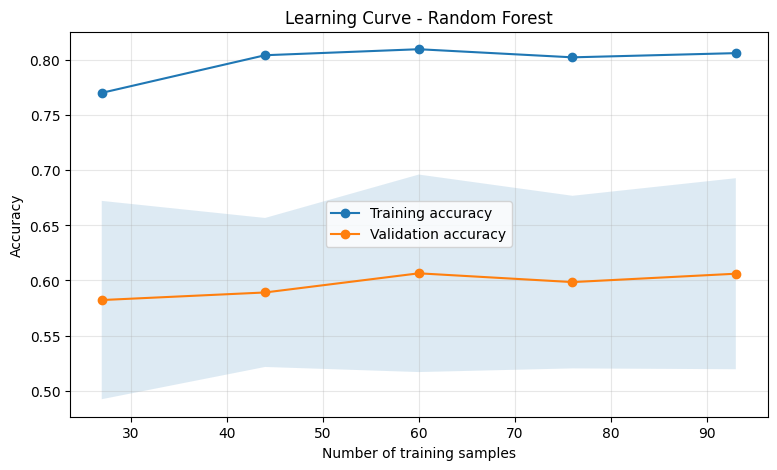

   Training samples  Train accuracy  Validation accuracy  Validation std
0                27           0.770                0.582           0.090
1                44           0.805                0.589           0.068
2                60           0.810                0.607           0.090
3                76           0.803                0.599           0.078
4                93           0.806                0.606           0.087


In [85]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import learning_curve, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

model = RandomForestClassifier(
    n_estimators=300,
    max_depth=3,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

train_sizes, train_scores, val_scores = learning_curve(
    estimator=model,
    X=X,
    y=y,
    train_sizes=np.linspace(0.3, 1.0, 5),
    cv=cv,
    scoring="accuracy",
    n_jobs=-1,
    shuffle=True,
    random_state=42
)

train_mean = train_scores.mean(axis=1)
val_mean = val_scores.mean(axis=1)

train_std = train_scores.std(axis=1)
val_std = val_scores.std(axis=1)

plt.figure(figsize=(9, 5))

plt.plot(train_sizes, train_mean, marker="o", label="Training accuracy")
plt.plot(train_sizes, val_mean, marker="o", label="Validation accuracy")

plt.fill_between(
    train_sizes,
    val_mean - val_std,
    val_mean + val_std,
    alpha=0.15
)

plt.xlabel("Number of training samples")
plt.ylabel("Accuracy")
plt.title("Learning Curve - Random Forest")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(pd.DataFrame({
    "Training samples": train_sizes,
    "Train accuracy": train_mean,
    "Validation accuracy": val_mean,
    "Validation std": val_std
}).round(3))

In [86]:
print(df["delta_ndcg"].describe())

print(
    "Near-tie queries:",
    (df["delta_ndcg"].abs() < 0.01).sum()
)

print(
    "Total queries:",
    len(df)
)

count    117.000000
mean      -0.107175
std        0.415235
min       -1.000000
25%       -0.369070
50%       -0.200253
75%        0.262802
max        1.000000
Name: delta_ndcg, dtype: float64
Near-tie queries: 0
Total queries: 117


In [87]:
feature_cols = [
    "intersection",
    "cosine_similarity",
    "mean_rank_displacement",
    "expansion_ratio",
    "query_coverage",
    "mean_TF_density"
]

analysis_df = df[feature_cols].copy()
analysis_df["delta_ndcg"] = df["delta_ndcg"]
analysis_df["target"] = df["original_or_expanded"]

print(
    analysis_df.groupby("target")[feature_cols]
    .mean()
    .T
    .round(3)
)

print("\nFeature correlation with delta_ndcg:")
print(
    analysis_df[feature_cols + ["delta_ndcg"]]
    .corr(numeric_only=True)["delta_ndcg"]
    .drop("delta_ndcg")
    .sort_values()
    .round(3)
)

target                  expanded  original
intersection               5.493     5.130
cosine_similarity          0.924     0.908
mean_rank_displacement     0.742     0.972
expansion_ratio            2.634     3.440
query_coverage             0.846     0.786
mean_TF_density            0.723     1.149

Feature correlation with delta_ndcg:
cosine_similarity        -0.219
query_coverage           -0.210
intersection             -0.099
mean_rank_displacement    0.207
expansion_ratio           0.246
mean_TF_density           0.288
Name: delta_ndcg, dtype: float64


### XGBClassifier

In [88]:
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    classification_report, confusion_matrix
)

In [89]:
xgb = XGBClassifier(
    n_estimators=500,
    learning_rate=0.01,
    max_depth=6,
    objective='binary:logistic', 
    eval_metric='logloss',         
    random_state=42,
    n_jobs=-1
)

In [90]:
xgb.fit(X_train, y_train)

,"objective objective: typing.Union[str, xgboost.objective.Objective, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'binary:logistic'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets im

In [91]:
y_pred = xgb.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Balanced Acc:", balanced_accuracy_score(y_test, y_pred))
print("F1 (macro):", f1_score(y_test, y_pred, average='macro'))
print("\n", classification_report(y_test, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))

Accuracy: 0.625
Balanced Acc: 0.5888888888888888
F1 (macro): 0.5901328273244781

               precision    recall  f1-score   support

           0       0.69      0.73      0.71        15
           1       0.50      0.44      0.47         9

    accuracy                           0.62        24
   macro avg       0.59      0.59      0.59        24
weighted avg       0.62      0.62      0.62        24


Confusion Matrix:
 [[11  4]
 [ 5  4]]


### Logistic Regression

In [92]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate

logistic = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        class_weight="balanced",
        random_state=42
    ))
])

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [93]:
results = cross_validate(
    logistic,
    X,
    y,
    cv=skf,
    scoring=["accuracy", "f1_macro"]
)

In [94]:
print("Accuracy:", results["test_accuracy"])
print("Mean Accuracy:", results["test_accuracy"].mean())
print("Std Accuracy:", results["test_accuracy"].std())

print("\nF1:", results["test_f1_macro"])
print("Mean F1:", results["test_f1_macro"].mean())
print("Std F1:", results["test_f1_macro"].std())

Accuracy: [0.58333333 0.75       0.60869565 0.65217391 0.65217391]
Mean Accuracy: 0.6492753623188406
Std Accuracy: 0.0568459671230585

F1: [0.57142857 0.74285714 0.59649123 0.64615385 0.65151515]
Mean F1: 0.6416891880049774
Std F1: 0.05887418389111483
